In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

resumen = pd.read_csv('../resultados/resumen.csv', dtype={'cpu_med_ms': str,
                                                           'aceleracion_computo': str,
                                                           'aceleracion_transferencias': str})

# Las corridas de CPU que superaron 120 s se guardaron como '>120s' y sus aceleraciones como '>X'.
# Se convierten a numero (120 s -> 120000 ms) y se marca la fila como cota inferior.
def a_numero(col):
    txt = resumen[col].fillna('').astype(str)
    es_cota = txt.str.startswith('>')
    en_seg = txt.str.endswith('s')
    valor = pd.to_numeric(txt.str.lstrip('>').str.rstrip('s'), errors='coerce')
    valor[en_seg] = valor[en_seg] * 1000.0
    return valor, es_cota

resumen['cpu_med_ms'], resumen['cpu_cota'] = a_numero('cpu_med_ms')
resumen['aceleracion_computo'], resumen['acel_cota'] = a_numero('aceleracion_computo')
resumen['aceleracion_transferencias'], _ = a_numero('aceleracion_transferencias')

# Dibuja barras; las que son cota inferior van rayadas y con la etiqueta '>='
def barras(ax, x, y, cota, color, offset=0.0, ancho=0.8, label=None):
    pos = [i + offset for i in range(len(x))]
    b = ax.bar(pos, list(y), width=ancho, color=color, edgecolor='black', label=label)
    for barra, c in zip(b, cota):
        if c:
            barra.set_hatch('//')
    ax.bar_label(b, labels=[('>= ' if c else '') + f'{v:,.2f}' for v, c in zip(y, cota)], fontsize=8)
    return pos

LEYENDA_COTA = Patch(facecolor='white', edgecolor='black', hatch='//', label='Cota inferior (CPU cortada a 120 s)')

print(resumen.drop(columns=['cpu_cota', 'acel_cota']).to_string())

        filtro resolucion mascara  hilos_bloque   cpu_med_ms  cpu_iqr_ms  cpu_std_ms  gpu_h2d_ms  gpu_kernel_ms  gpu_ker_iqr_ms  gpu_ker_std_ms  gpu_d2h_ms  gpu_total_ms  gpu_tot_iqr_ms  gpu_tot_std_ms  aceleracion_computo  aceleracion_transferencias  error_abs_max       mae
0        media  2050x2050     3x3           256    8647.0459     60.3430     37.7592      0.4870         0.4403          0.0031          0.0052      2.0063        2.9365          0.0280          0.0488             19638.10                     2944.70       0.000039  0.000006
1        media  4000x4000     3x3           256   33190.5853     84.2051    407.1704      2.0630         1.5872          0.0092          0.0051      7.7228       11.4704          0.6921          0.4487             20911.41                     2893.59       0.000041  0.000006
2      nitidez  4000x4000     3x3           256   32894.2751     50.4869     62.8200      2.0874         1.5902          0.0141          0.0139      7.9739       11.7144   

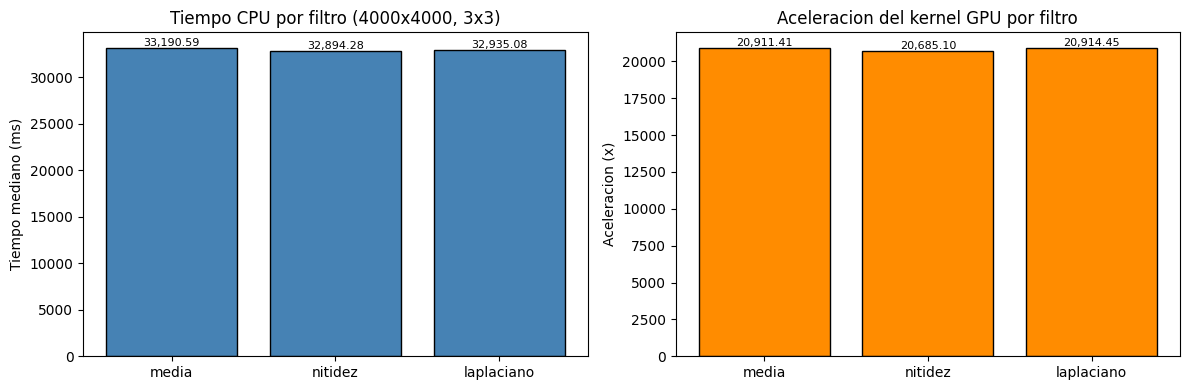

In [2]:
# Experimento 1: comparar filtros 3x3 sobre 4000x4000
exp1 = resumen[
    (resumen['resolucion'] == '4000x4000') &
    (resumen['mascara'] == '3x3') &
    (resumen['hilos_bloque'] == 256) &
    (resumen['filtro'].isin(['media', 'nitidez', 'laplaciano']))
].drop_duplicates(subset='filtro', keep='first')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
barras(axes[0], exp1['filtro'], exp1['cpu_med_ms'], exp1['cpu_cota'], 'steelblue')
axes[0].set_xticks(range(len(exp1)), exp1['filtro'])
axes[0].set_title('Tiempo CPU por filtro (4000x4000, 3x3)')
axes[0].set_ylabel('Tiempo mediano (ms)')
barras(axes[1], exp1['filtro'], exp1['aceleracion_computo'], exp1['acel_cota'], 'darkorange')
axes[1].set_xticks(range(len(exp1)), exp1['filtro'])
axes[1].set_title('Aceleracion del kernel GPU por filtro')
axes[1].set_ylabel('Aceleracion (x)')
plt.tight_layout()
plt.savefig('../resultados/exp1_filtros.png', dpi=150)
plt.show()

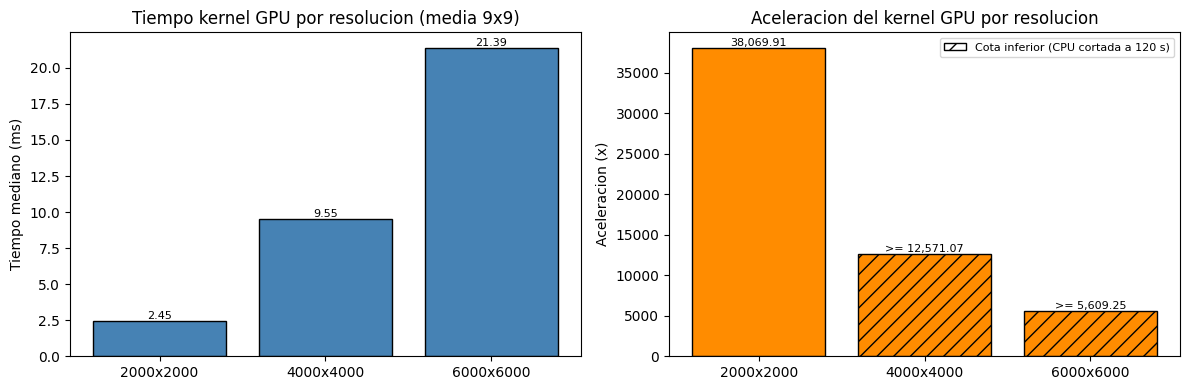

In [3]:
# Experimento 2: comparar resoluciones con media 9x9
# 2000x2000 y 6000x6000 son unicos; 4000x4000 aparece varias veces -> keep='first'
exp2 = resumen[
    (resumen['filtro'] == 'media') &
    (resumen['mascara'] == '9x9') &
    (resumen['hilos_bloque'] == 256) &
    (resumen['resolucion'].isin(['2000x2000', '4000x4000', '6000x6000']))
].drop_duplicates(subset='resolucion', keep='first')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
barras(axes[0], exp2['resolucion'], exp2['gpu_kernel_ms'], [False] * len(exp2), 'steelblue')
axes[0].set_xticks(range(len(exp2)), exp2['resolucion'])
axes[0].set_title('Tiempo kernel GPU por resolucion (media 9x9)')
axes[0].set_ylabel('Tiempo mediano (ms)')
barras(axes[1], exp2['resolucion'], exp2['aceleracion_computo'], exp2['acel_cota'], 'darkorange')
axes[1].set_xticks(range(len(exp2)), exp2['resolucion'])
axes[1].set_title('Aceleracion del kernel GPU por resolucion')
axes[1].set_ylabel('Aceleracion (x)')
axes[1].legend(handles=[LEYENDA_COTA], fontsize=8)
plt.tight_layout()
plt.savefig('../resultados/exp2_resolucion.png', dpi=150)
plt.show()

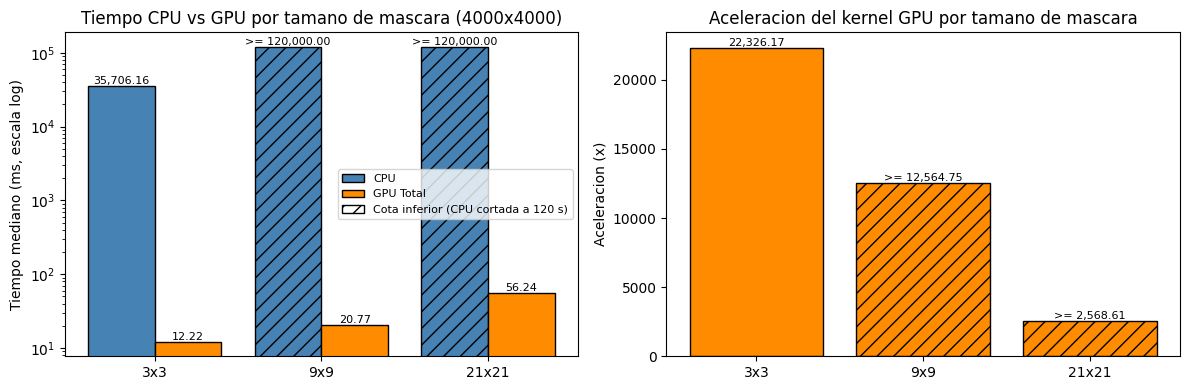

In [4]:
# Experimento 3: comparar tamanos de mascara sobre 4000x4000
# 21x21 aparece una sola vez en todo el CSV -> se usa como ancla de las 3 filas del Exp 3
idx_21 = resumen[resumen['mascara'] == '21x21'].index[0]
exp3 = resumen.iloc[idx_21 - 2 : idx_21 + 1].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Escala logaritmica: la CPU (>= 35 s) y la GPU (decenas de ms) difieren en varios ordenes de magnitud
barras(axes[0], exp3['mascara'], exp3['cpu_med_ms'], exp3['cpu_cota'], 'steelblue',
       offset=-0.2, ancho=0.4, label='CPU')
barras(axes[0], exp3['mascara'], exp3['gpu_total_ms'], [False] * len(exp3), 'darkorange',
       offset=0.2, ancho=0.4, label='GPU Total')
axes[0].set_yscale('log')
axes[0].set_xticks(range(len(exp3)), exp3['mascara'])
axes[0].set_title('Tiempo CPU vs GPU por tamano de mascara (4000x4000)')
axes[0].set_ylabel('Tiempo mediano (ms, escala log)')
axes[0].legend(handles=axes[0].get_legend_handles_labels()[0] + [LEYENDA_COTA], fontsize=8)
barras(axes[1], exp3['mascara'], exp3['aceleracion_computo'], exp3['acel_cota'], 'darkorange')
axes[1].set_xticks(range(len(exp3)), exp3['mascara'])
axes[1].set_title('Aceleracion del kernel GPU por tamano de mascara')
axes[1].set_ylabel('Aceleracion (x)')
plt.tight_layout()
plt.savefig('../resultados/exp3_mascara.png', dpi=150)
plt.show()

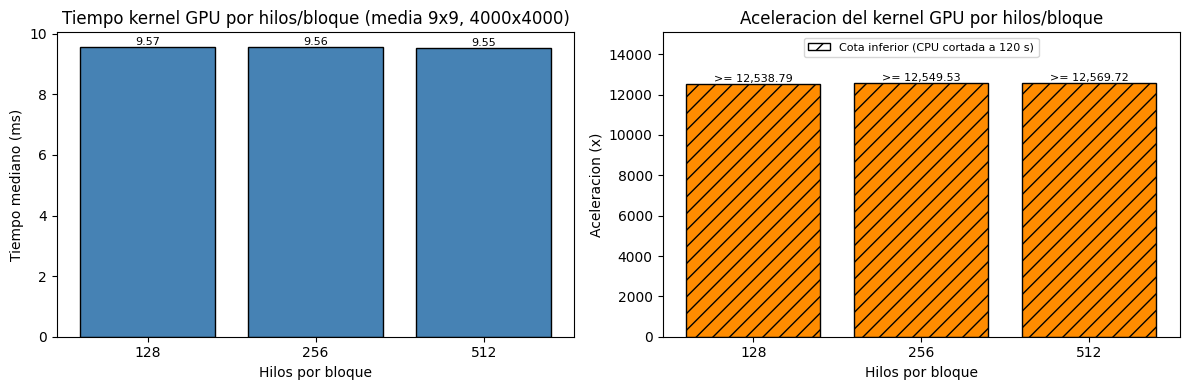

In [5]:
# Experimento 4: comparar hilos/bloque con media 9x9 sobre 4000x4000
# 128 y 512 hilos son unicos; 256 aparece varias veces -> keep='last' toma el de Exp 4
exp4 = resumen[
    (resumen['filtro'] == 'media') &
    (resumen['mascara'] == '9x9') &
    (resumen['resolucion'] == '4000x4000') &
    (resumen['hilos_bloque'].isin([128, 256, 512]))
].drop_duplicates(subset='hilos_bloque', keep='last')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
barras(axes[0], exp4['hilos_bloque'].astype(str), exp4['gpu_kernel_ms'], [False] * len(exp4), 'steelblue')
axes[0].set_xticks(range(len(exp4)), exp4['hilos_bloque'].astype(str))
axes[0].set_title('Tiempo kernel GPU por hilos/bloque (media 9x9, 4000x4000)')
axes[0].set_xlabel('Hilos por bloque')
axes[0].set_ylabel('Tiempo mediano (ms)')
barras(axes[1], exp4['hilos_bloque'].astype(str), exp4['aceleracion_computo'], exp4['acel_cota'], 'darkorange')
axes[1].set_xticks(range(len(exp4)), exp4['hilos_bloque'].astype(str))
axes[1].set_title('Aceleracion del kernel GPU por hilos/bloque')
axes[1].set_xlabel('Hilos por bloque')
axes[1].set_ylabel('Aceleracion (x)')
axes[1].set_ylim(0, exp4['aceleracion_computo'].max() * 1.2)
axes[1].legend(handles=[LEYENDA_COTA], fontsize=8, loc='upper center')
plt.tight_layout()
plt.savefig('../resultados/exp4_hilos.png', dpi=150)
plt.show()